# 04 Feature Engineering

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import pandas as pd

df = pd.read_csv(ROOT / "data/processed/midfielder_clusters.csv")

keywords = ["pass", "progress", "carr", "third", "chance", "assist"]

matching_columns = [
    col for col in df.columns
    if any(keyword in col.lower() for keyword in keywords)
]


display(df[["player_name", *matching_columns]].head())


,player_name,scoring.assists,scoring.goals_assists_sum,scoring.big_chances_created,scoring.big_chances_missed,scoring.expected_assists,passing.total_passes,passing.accurate_passes,passing.inaccurate_passes,passing.pass_accuracy,passing.key_passes,passing.accurate_crosses,passing.accurate_crosses_percentage,passing.accurate_own_half_passes,passing.accurate_opposition_half_passes,passing.accurate_final_third_passes,scoring.expected_assists_per90
0,Bruno Guimarães,5,14,7,0,4.76,1451,1250,201,86.1,46,21,25.6,0,0,0,0.174501
1,Declan Rice,5,9,17,0,6.69,2136,1865,271,87.3,64,47,26.4,0,0,0,0.194288
2,Eberechi Eze,2,9,4,0,2.74,666,565,101,84.8,16,2,16.7,0,0,0,0.129789
3,Martin Ødegaard,6,7,6,0,3.49,828,701,127,84.7,40,6,27.3,0,0,0,0.229270
4,Martín Zubimendi,1,6,1,0,2.17,1928,1684,244,87.3,19,3,25.0,0,0,0,0.065078


### New Features to Test

- **Key passes / 90:** Find frequent chance creators.
- **Accurate final-third passes / 90:** Highlights involvement in attacking-third passing.
- **Accurate crosses / 90:** Distinguish wide creators yuhj from central creators.
- **Accurate passes / 90:** Highlights involvement in possession circulation.
- **Accurate own-half passes / 90:** Highlights deeper passing involvement and potential buildup roles.

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from src.preprocessing import MODEL_FEATURES
from src.utils import load_config

config = load_config(ROOT / "config/config.yaml")

df = pd.read_csv(
    ROOT / "data/processed/midfielder_clusters.csv"
)

baseline_features = list(MODEL_FEATURES)
random_state = config["training"]["random_state"]
n_clusters = config["model"]["n_clusters"]

In [4]:
candidate_counts = [
    "passing.key_passes",
    "passing.accurate_final_third_passes",
    "passing.accurate_crosses",
    "passing.accurate_passes",
    "passing.accurate_own_half_passes",
]

required_columns = ["minutes_played", *baseline_features, *candidate_counts]

for feature in candidate_counts:
    df[f"{feature}_per90"] = (
        df[feature] * 90 / df["minutes_played"]
    )

candidate_features = [
    f"{feature}_per90" for feature in candidate_counts
]

experiments = {"baseline": baseline_features}

for feature in candidate_features:
    experiments[f"add: {feature}"] = baseline_features + [feature]

expanded_features = baseline_features + candidate_features

experiments["all_new_features"] = expanded_features
experiments["without_accurate_passes"] = [
    f for f in expanded_features
    if f != "passing.accurate_passes_per90"
]
experiments["without_own_half_passes"] = [
    f for f in expanded_features
    if f != "passing.accurate_own_half_passes_per90"
]

results = []
experiment_labels = {}

for name, features in experiments.items():
    X_scaled = StandardScaler().fit_transform(df[features])

    model = KMeans(
        n_clusters=n_clusters,
        random_state=random_state,
        n_init=10,
    )
    labels = model.fit_predict(X_scaled)

    experiment_labels[name] = labels

    results.append({
        "experiment": name,
        "features": len(features),
        "silhouette": silhouette_score(X_scaled, labels),
        "cluster_sizes": pd.Series(labels).value_counts().sort_index().tolist(),
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values("silhouette", ascending=False)
    .round({"silhouette": 3})
)

DuplicateError: Expected unique column names, got:
- 'passing.key_passes_per90' 2 times

In [ ]:
display(
    df[
        [
            "passing.accurate_final_third_passes_per90",
            "passing.accurate_own_half_passes_per90",
        ]
    ].describe()
)

columns = [
    "passing.accurate_final_third_passes",
    "passing.accurate_own_half_passes",
]

raw_df = pd.read_csv(ROOT / config["data"]["path"])

display(raw_df[columns].describe())
display(raw_df[columns].head(10))

,passing.accurate_final_third_passes_per90,passing.accurate_own_half_passes_per90
count,92.0,92.0
mean,0.0,0.0
std,0.0,0.0
min,0.0,0.0
25%,0.0,0.0
50%,0.0,0.0
75%,0.0,0.0
max,0.0,0.0


,passing.accurate_final_third_passes,passing.accurate_own_half_passes
count,161.0,161.0
mean,0.0,0.0
std,0.0,0.0
min,0.0,0.0
25%,0.0,0.0
50%,0.0,0.0
75%,0.0,0.0
max,0.0,0.0


,passing.accurate_final_third_passes,passing.accurate_own_half_passes
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
5,0,0
6,0,0
7,0,0
8,0,0
9,0,0


### Excluded Features

Accurate final-third passes and accurate own-half passes were excluded because both columns contain only zeros in the raw dataset. They provide
no variation for clustering and cannot support conclusions about player roles.

Test Candidate: Baseline + accurate_crosses_per90:

Cluster 0 contains midfielders of different roles, grouped by wide delivery outputs.

In [ ]:
inspection = df.copy()
inspection["experiment_cluster"] = experiment_labels[
    "add: passing.accurate_crosses_per90"
]

features = baseline_features + ["passing.accurate_crosses_per90"]

display(
    inspection.groupby("experiment_cluster")[features].mean().round(3)
)

for cluster, players in inspection.groupby("experiment_cluster"):
    print(f"\nCluster {cluster}")

    display(
        players[
            ["player_name", "minutes_played", *features]
        ].sort_values("minutes_played", ascending=False).head(10)
    )

,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90,passing.accurate_crosses_per90
experiment_cluster,,,,,
0,0.116,0.211,2.103,0.910,1.497
1,0.068,0.066,2.266,1.130,0.278
2,0.208,0.125,1.408,0.462,0.381



Cluster 0


,player_name,minutes_played,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90,passing.accurate_crosses_per90
37,James Garner,3414,0.051406,0.149736,3.163445,1.555360,1.397188
55,Elliot Anderson,3334,0.075315,0.123635,2.807439,1.106779,1.376725
52,Dominik Szoboszlai,3233,0.129168,0.180668,1.558924,0.835138,1.892979
1,Declan Rice,3099,0.088577,0.194288,2.032914,1.074540,1.364956
60,Bruno Fernandes,3066,0.303229,0.378082,1.585127,0.587084,1.614481
31,Adam Wharton,2562,0.051639,0.250117,2.459016,0.948478,0.983607
45,Anton Stach,2378,0.105593,0.163877,2.460050,0.756939,1.703112
17,Mathias Jensen,2277,0.085375,0.229644,1.620553,0.830040,1.501976
57,Phil Foden,2107,0.251590,0.194352,1.452302,0.384433,1.708590
18,Mikkel Damsgaard,2078,0.108277,0.226083,2.468720,1.082772,1.212705



Cluster 1


,player_name,minutes_played,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90,passing.accurate_crosses_per90
48,Ethan Ampadu,3123,0.068876,0.062824,2.334294,1.440922,0.288184
83,Mateus Fernandes,3024,0.056548,0.083929,3.065476,1.041667,0.357143
4,Martín Zubimendi,3001,0.081273,0.065078,2.039320,1.169610,0.089970
54,Ryan Gravenberch,2996,0.054372,0.070294,1.772363,1.441923,0.000000
43,Sander Berge,2911,0.046067,0.044830,1.762281,0.772930,0.092752
77,Granit Xhaka,2903,0.030382,0.111299,1.550121,0.899070,0.713055
79,Noah Sadiki,2894,0.043849,0.043227,1.430546,1.057360,0.124395
11,Alex Scott,2859,0.115845,0.090031,1.888772,1.133263,0.440714
8,João Gomes,2843,0.038621,0.063630,3.387267,1.139641,0.348224
29,Moisés Caicedo,2802,0.044004,0.073233,2.794433,1.895075,0.064240



Cluster 2


,player_name,minutes_played,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90,passing.accurate_crosses_per90
30,Morgan Rogers,3285,0.178630,0.112603,1.150685,0.356164,0.082192
56,Enzo Fernández,3121,0.311439,0.199840,1.528356,0.605575,0.461391
73,Morgan Gibbs-White,3110,0.300386,0.081318,0.578778,0.376206,0.260450
38,Kiernan Dewsbury-Hall,2635,0.142087,0.176926,1.776091,0.409867,0.717268
0,Bruno Guimarães,2455,0.196864,0.174501,2.272912,0.549898,0.769857
53,Florian Wirtz,2388,0.256658,0.186935,1.281407,0.414573,0.188442
88,Tomáš Souček,2215,0.221038,0.020722,1.747178,0.650113,0.000000
27,Cole Palmer,1965,0.501069,0.109008,1.145038,0.687023,0.229008
40,Emile Smith Rowe,1943,0.210757,0.049563,1.621204,1.019043,0.046320
2,Eberechi Eze,1900,0.229737,0.129789,0.900000,0.521053,0.094737


Test (accurate crosses + key passes) 

Clusters

0:	Creative / delivery-oriented |	Highest key passes (2.047), xA (0.207), and crosses (1.272)

1:	Defensive-minded	| Highest tackles (2.244) and interceptions (1.149), lowest attacking output

2:	Goal-threats|	Highest xG (0.221)

In [ ]:
inspection = df.copy()
inspection["experiment_cluster"] = experiment_labels[
    "without_accurate_passes"
]

features = baseline_features + ["passing.key_passes_per90", "passing.accurate_crosses_per90"]

display(
    inspection.groupby("experiment_cluster")[features].mean().round(3)
)

for cluster, players in inspection.groupby("experiment_cluster"):
    print(f"\nCluster {cluster}")

    display(
        players[
            ["player_name", "minutes_played", *features]
        ].sort_values("minutes_played", ascending=False).head(10)
    )

,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90,passing.key_passes_per90,passing.accurate_crosses_per90
experiment_cluster,,,,,,
0,0.121,0.207,2.090,0.800,2.047,1.272
1,0.068,0.066,2.244,1.149,0.782,0.288
2,0.221,0.114,1.344,0.430,1.198,0.349



Cluster 0


,player_name,minutes_played,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90,passing.key_passes_per90,passing.accurate_crosses_per90
37,James Garner,3414,0.051406,0.149736,3.163445,1.555360,1.476274,1.397188
55,Elliot Anderson,3334,0.075315,0.123635,2.807439,1.106779,1.484703,1.376725
52,Dominik Szoboszlai,3233,0.129168,0.180668,1.558924,0.835138,2.171358,1.892979
1,Declan Rice,3099,0.088577,0.194288,2.032914,1.074540,1.858664,1.364956
60,Bruno Fernandes,3066,0.303229,0.378082,1.585127,0.587084,4.021526,1.614481
31,Adam Wharton,2562,0.051639,0.250117,2.459016,0.948478,1.545667,0.983607
0,Bruno Guimarães,2455,0.196864,0.174501,2.272912,0.549898,1.686354,0.769857
45,Anton Stach,2378,0.105593,0.163877,2.460050,0.756939,2.384357,1.703112
17,Mathias Jensen,2277,0.085375,0.229644,1.620553,0.830040,1.383399,1.501976
57,Phil Foden,2107,0.251590,0.194352,1.452302,0.384433,2.349312,1.708590



Cluster 1


,player_name,minutes_played,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90,passing.key_passes_per90,passing.accurate_crosses_per90
48,Ethan Ampadu,3123,0.068876,0.062824,2.334294,1.440922,0.576369,0.288184
83,Mateus Fernandes,3024,0.056548,0.083929,3.065476,1.041667,1.101190,0.357143
4,Martín Zubimendi,3001,0.081273,0.065078,2.039320,1.169610,0.569810,0.089970
54,Ryan Gravenberch,2996,0.054372,0.070294,1.772363,1.441923,0.871162,0.000000
43,Sander Berge,2911,0.046067,0.044830,1.762281,0.772930,0.649261,0.092752
77,Granit Xhaka,2903,0.030382,0.111299,1.550121,0.899070,1.054082,0.713055
79,Noah Sadiki,2894,0.043849,0.043227,1.430546,1.057360,0.590878,0.124395
11,Alex Scott,2859,0.115845,0.090031,1.888772,1.133263,0.881427,0.440714
8,João Gomes,2843,0.038621,0.063630,3.387267,1.139641,0.506507,0.348224
29,Moisés Caicedo,2802,0.044004,0.073233,2.794433,1.895075,0.610278,0.064240



Cluster 2


,player_name,minutes_played,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90,passing.key_passes_per90,passing.accurate_crosses_per90
30,Morgan Rogers,3285,0.178630,0.112603,1.150685,0.356164,1.287671,0.082192
56,Enzo Fernández,3121,0.311439,0.199840,1.528356,0.605575,1.989747,0.461391
73,Morgan Gibbs-White,3110,0.300386,0.081318,0.578778,0.376206,1.418006,0.260450
38,Kiernan Dewsbury-Hall,2635,0.142087,0.176926,1.776091,0.409867,1.263757,0.717268
53,Florian Wirtz,2388,0.256658,0.186935,1.281407,0.414573,2.298995,0.188442
88,Tomáš Souček,2215,0.221038,0.020722,1.747178,0.650113,0.446953,0.000000
27,Cole Palmer,1965,0.501069,0.109008,1.145038,0.687023,1.145038,0.229008
40,Emile Smith Rowe,1943,0.210757,0.049563,1.621204,1.019043,0.833762,0.046320
2,Eberechi Eze,1900,0.229737,0.129789,0.900000,0.521053,0.757895,0.094737
21,Jack Hinshelwood,1750,0.243771,0.115200,0.977143,0.257143,0.771429,0.000000


Test (accurate_passes)


In [ ]:
inspection = df.copy()
inspection["experiment_cluster"] = experiment_labels[
    "add: passing.accurate_passes_per90"
]

features = baseline_features + ["passing.accurate_passes_per90"]

display(
    inspection.groupby("experiment_cluster")[features].mean().round(3)
)

for cluster, players in inspection.groupby("experiment_cluster"):
    print(f"\nCluster {cluster}")

    display(
        players[
            ["player_name", "minutes_played", *features]
        ].sort_values("minutes_played", ascending=False).head(10)
    )

,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90,passing.accurate_passes_per90
experiment_cluster,,,,,
0,0.063,0.072,2.357,1.215,41.187
1,0.161,0.223,1.661,0.666,46.816
2,0.176,0.103,1.600,0.540,25.747



Cluster 0


,player_name,minutes_played,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90,passing.accurate_passes_per90
37,James Garner,3414,0.051406,0.149736,3.163445,1.555360,41.230228
55,Elliot Anderson,3334,0.075315,0.123635,2.807439,1.106779,55.014997
48,Ethan Ampadu,3123,0.068876,0.062824,2.334294,1.440922,42.708934
83,Mateus Fernandes,3024,0.056548,0.083929,3.065476,1.041667,40.654762
4,Martín Zubimendi,3001,0.081273,0.065078,2.039320,1.169610,50.503166
54,Ryan Gravenberch,2996,0.054372,0.070294,1.772363,1.441923,49.656208
43,Sander Berge,2911,0.046067,0.044830,1.762281,0.772930,48.014428
77,Granit Xhaka,2903,0.030382,0.111299,1.550121,0.899070,46.875646
79,Noah Sadiki,2894,0.043849,0.043227,1.430546,1.057360,29.357291
11,Alex Scott,2859,0.115845,0.090031,1.888772,1.133263,37.208814



Cluster 1


,player_name,minutes_played,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90,passing.accurate_passes_per90
52,Dominik Szoboszlai,3233,0.129168,0.180668,1.558924,0.835138,53.420971
56,Enzo Fernández,3121,0.311439,0.199840,1.528356,0.605575,50.608779
1,Declan Rice,3099,0.088577,0.194288,2.032914,1.074540,54.162633
60,Bruno Fernandes,3066,0.303229,0.378082,1.585127,0.587084,48.111546
31,Adam Wharton,2562,0.051639,0.250117,2.459016,0.948478,34.320843
0,Bruno Guimarães,2455,0.196864,0.174501,2.272912,0.549898,45.824847
53,Florian Wirtz,2388,0.256658,0.186935,1.281407,0.414573,45.263819
17,Mathias Jensen,2277,0.085375,0.229644,1.620553,0.830040,35.849802
57,Phil Foden,2107,0.251590,0.194352,1.452302,0.384433,45.576649
18,Mikkel Damsgaard,2078,0.108277,0.226083,2.468720,1.082772,31.443696



Cluster 2


,player_name,minutes_played,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90,passing.accurate_passes_per90
30,Morgan Rogers,3285,0.178630,0.112603,1.150685,0.356164,21.835616
73,Morgan Gibbs-White,3110,0.300386,0.081318,0.578778,0.376206,28.360129
38,Kiernan Dewsbury-Hall,2635,0.142087,0.176926,1.776091,0.409867,28.895636
45,Anton Stach,2378,0.105593,0.163877,2.460050,0.756939,27.476871
88,Tomáš Souček,2215,0.221038,0.020722,1.747178,0.650113,28.361174
27,Cole Palmer,1965,0.501069,0.109008,1.145038,0.687023,32.198473
40,Emile Smith Rowe,1943,0.210757,0.049563,1.621204,1.019043,38.816264
2,Eberechi Eze,1900,0.229737,0.129789,0.900000,0.521053,26.763158
21,Jack Hinshelwood,1750,0.243771,0.115200,0.977143,0.257143,26.845714
66,Jacob Murphy,1627,0.168162,0.146589,0.885065,0.331899,20.245851


Test (all new features)

In [ ]:
inspection = df.copy()
inspection["experiment_cluster"] = experiment_labels[
    "all_new_features"
]

features = baseline_features + [ 
    "passing.key_passes_per90",
    "passing.accurate_crosses_per90",
    "passing.accurate_passes_per90",]

display(
    inspection.groupby("experiment_cluster")[features].mean().round(3)
)

for cluster, players in inspection.groupby("experiment_cluster"):
    print(f"\nCluster {cluster}")

    display(
        players[
            ["player_name", "minutes_played", *features]
        ].sort_values("minutes_played", ascending=False).head(10)
    )

,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90,passing.key_passes_per90,passing.accurate_crosses_per90,passing.accurate_passes_per90
experiment_cluster,,,,,,,
0,0.063,0.070,2.305,1.202,0.823,0.341,42.016
1,0.173,0.225,1.839,0.684,2.188,1.238,42.121
2,0.169,0.096,1.577,0.541,1.044,0.338,25.701



Cluster 0


,player_name,minutes_played,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90,passing.key_passes_per90,passing.accurate_crosses_per90,passing.accurate_passes_per90
37,James Garner,3414,0.051406,0.149736,3.163445,1.555360,1.476274,1.397188,41.230228
55,Elliot Anderson,3334,0.075315,0.123635,2.807439,1.106779,1.484703,1.376725,55.014997
48,Ethan Ampadu,3123,0.068876,0.062824,2.334294,1.440922,0.576369,0.288184,42.708934
83,Mateus Fernandes,3024,0.056548,0.083929,3.065476,1.041667,1.101190,0.357143,40.654762
4,Martín Zubimendi,3001,0.081273,0.065078,2.039320,1.169610,0.569810,0.089970,50.503166
54,Ryan Gravenberch,2996,0.054372,0.070294,1.772363,1.441923,0.871162,0.000000,49.656208
43,Sander Berge,2911,0.046067,0.044830,1.762281,0.772930,0.649261,0.092752,48.014428
77,Granit Xhaka,2903,0.030382,0.111299,1.550121,0.899070,1.054082,0.713055,46.875646
79,Noah Sadiki,2894,0.043849,0.043227,1.430546,1.057360,0.590878,0.124395,29.357291
11,Alex Scott,2859,0.115845,0.090031,1.888772,1.133263,0.881427,0.440714,37.208814



Cluster 1


,player_name,minutes_played,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90,passing.key_passes_per90,passing.accurate_crosses_per90,passing.accurate_passes_per90
52,Dominik Szoboszlai,3233,0.129168,0.180668,1.558924,0.835138,2.171358,1.892979,53.420971
56,Enzo Fernández,3121,0.311439,0.199840,1.528356,0.605575,1.989747,0.461391,50.608779
1,Declan Rice,3099,0.088577,0.194288,2.032914,1.074540,1.858664,1.364956,54.162633
60,Bruno Fernandes,3066,0.303229,0.378082,1.585127,0.587084,4.021526,1.614481,48.111546
31,Adam Wharton,2562,0.051639,0.250117,2.459016,0.948478,1.545667,0.983607,34.320843
0,Bruno Guimarães,2455,0.196864,0.174501,2.272912,0.549898,1.686354,0.769857,45.824847
53,Florian Wirtz,2388,0.256658,0.186935,1.281407,0.414573,2.298995,0.188442,45.263819
45,Anton Stach,2378,0.105593,0.163877,2.460050,0.756939,2.384357,1.703112,27.476871
17,Mathias Jensen,2277,0.085375,0.229644,1.620553,0.830040,1.383399,1.501976,35.849802
57,Phil Foden,2107,0.251590,0.194352,1.452302,0.384433,2.349312,1.708590,45.576649



Cluster 2


,player_name,minutes_played,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90,passing.key_passes_per90,passing.accurate_crosses_per90,passing.accurate_passes_per90
30,Morgan Rogers,3285,0.178630,0.112603,1.150685,0.356164,1.287671,0.082192,21.835616
73,Morgan Gibbs-White,3110,0.300386,0.081318,0.578778,0.376206,1.418006,0.260450,28.360129
38,Kiernan Dewsbury-Hall,2635,0.142087,0.176926,1.776091,0.409867,1.263757,0.717268,28.895636
88,Tomáš Souček,2215,0.221038,0.020722,1.747178,0.650113,0.446953,0.000000,28.361174
27,Cole Palmer,1965,0.501069,0.109008,1.145038,0.687023,1.145038,0.229008,32.198473
40,Emile Smith Rowe,1943,0.210757,0.049563,1.621204,1.019043,0.833762,0.046320,38.816264
2,Eberechi Eze,1900,0.229737,0.129789,0.900000,0.521053,0.757895,0.094737,26.763158
21,Jack Hinshelwood,1750,0.243771,0.115200,0.977143,0.257143,0.771429,0.000000,26.845714
66,Jacob Murphy,1627,0.168162,0.146589,0.885065,0.331899,1.272280,1.327597,20.245851
34,Will Hughes,1577,0.059924,0.103868,1.540900,0.856056,1.198478,0.684845,31.445783


## More Baseline Experiments

Use the original four-feature model as the baseline to evaluate:

1. **Cluster count:** Compare k = 2 through 8.
2. **Playing-time threshold:** Compare 450 and 900 minimum minutes.


In [16]:
from sklearn.metrics import davies_bouldin_score

baseline_features = [
    "scoring.expected_goals_per90",
    "scoring.expected_assists_per90",
    "defending.tackles_per90",
    "defending.interceptions_per90",
]

new_counts = [
    "passing.key_passes",
    "passing.accurate_crosses"
]

features = baseline_features + [
    f"{column}_per90" for column in new_counts
]

# Load the original processed dataset.
v1_df = pd.read_csv(
    ROOT / "data/processed/midfielder_clusters.csv"
)

# Validate and convert the required numeric columns.
required = ["minutes_played", *baseline_features, *new_counts]

missing = [column for column in required if column not in v1_df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

v1_df[required] = v1_df[required].apply(
    pd.to_numeric, errors="raise"
)

if v1_df[required].isna().any().any():
    raise ValueError("Missing values found. Inspect them before testing.")

if (v1_df["minutes_played"] <= 0).any():
    raise ValueError("Minutes played must be greater than zero.")

# Create the additional per-90 features.
for column in new_counts:
    v1_df[f"{column}_per90"] = (
        v1_df[column] * 90 / v1_df["minutes_played"]
    )

results = []
threshold_assignments = {}

for min_minutes in [450, 900]:
    eligible = v1_df.loc[
        v1_df["minutes_played"] >= min_minutes
    ].copy()

    X_scaled = StandardScaler().fit_transform(eligible[features])

    for k in range(2, 9):
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10,
        )
        labels = model.fit_predict(X_scaled)

        threshold_assignments[(min_minutes, k)] = (
            eligible.assign(experiment_cluster=labels)
        )

        results.append({
            "min_minutes": min_minutes,
            "players": len(eligible),
            "k": k,
            "silhouette": silhouette_score(X_scaled, labels),
            "davies_bouldin": davies_bouldin_score(X_scaled, labels),
            "cluster_sizes": (
                pd.Series(labels)
                .value_counts()
                .sort_index()
                .tolist()
            ),
        })

threshold_results = pd.DataFrame(results)

display(
    threshold_results.round({
        "silhouette": 3,
        "davies_bouldin": 3,
    })
)

,min_minutes,players,k,silhouette,davies_bouldin,cluster_sizes
0,450,92,2,0.326,1.284,"[31, 61]"
1,450,92,3,0.302,1.198,"[19, 51, 22]"
2,450,92,4,0.253,1.252,"[40, 11, 12, 29]"
3,450,92,5,0.222,1.167,"[13, 36, 21, 20, 2]"
4,450,92,6,0.222,1.224,"[25, 12, 12, 12, 29, 2]"
5,450,92,7,0.221,1.155,"[2, 30, 21, 13, 12, 12, 2]"
6,450,92,8,0.229,1.086,"[12, 17, 13, 29, 6, 2, 2, 11]"
7,900,83,2,0.345,1.232,"[56, 27]"
8,900,83,3,0.329,1.134,"[49, 21, 13]"
9,900,83,4,0.215,1.297,"[18, 16, 35, 14]"


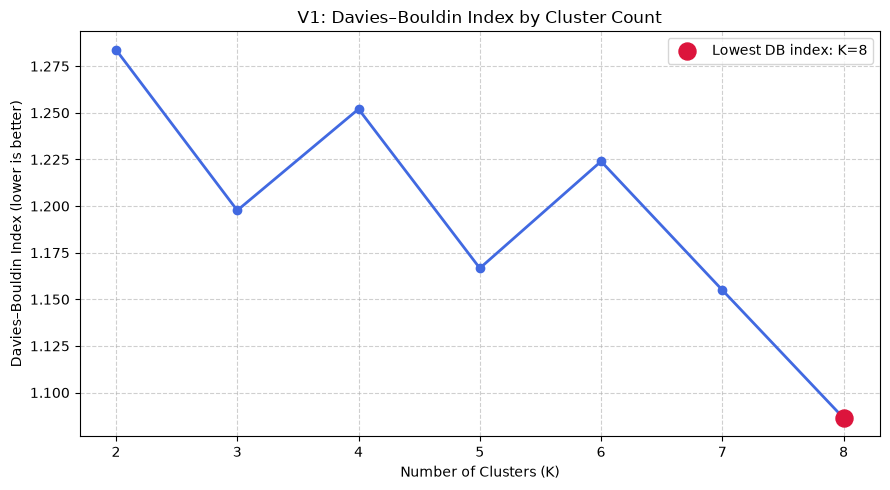

In [17]:
import matplotlib.pyplot as plt

X_scaled = StandardScaler().fit_transform(df[features])

k_values = list(range(2, 9))  # K = 2 through 8
db_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    score = davies_bouldin_score(X_scaled, labels)
    db_scores.append(score)

plt.figure(figsize=(9, 5))
plt.plot(
    k_values, db_scores,
    marker="o", color="royalblue", linewidth=2,
)

min_idx = db_scores.index(min(db_scores))
best_k = k_values[min_idx]

plt.scatter(
    best_k,
    db_scores[min_idx],
    color="crimson",
    s=150,
    zorder=5,
    label=f"Lowest DB index: K={best_k}",
)

plt.title("V1: Davies–Bouldin Index by Cluster Count")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Davies–Bouldin Index (lower is better)")
plt.xticks(k_values)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [22]:
from sklearn.metrics import adjusted_rand_score

clusters_450 = threshold_assignments[(450, 3)]
clusters_900 = threshold_assignments[(900, 3)]

shared = clusters_450[
    ["player_name", "experiment_cluster"]
].join(
    clusters_900[["experiment_cluster"]],
    how="inner",
    suffixes=("_450", "_900"),
    validate="one_to_one",
)

ari = adjusted_rand_score(
    shared["experiment_cluster_450"],
    shared["experiment_cluster_900"],
)

print("Shared players:", len(shared))
print(f"Adjusted Rand Index: {ari:.3f}")

# Show how groups correspond across thresholds.
display(
    pd.crosstab(
        shared["experiment_cluster_450"],
        shared["experiment_cluster_900"],
        rownames=["450-minute cluster"],
        colnames=["900-minute cluster"],
    )
)

Shared players: 83
Adjusted Rand Index: 0.887


900-minute cluster,0,1,2
450-minute cluster,,,
0,0,19,0
1,47,0,0
2,2,2,13


In [23]:
display(
    clusters_900.groupby("experiment_cluster")[features]
    .mean()
    .round(3)
)

for cluster, players in clusters_900.groupby("experiment_cluster"):
    print(f"\n900-minute sample — Cluster {cluster}")

    display(
        players[
            ["player_name", "minutes_played", *features]
        ].sort_values("minutes_played", ascending=False).head(10)
    )

,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90,passing.key_passes_per90,passing.accurate_crosses_per90
experiment_cluster,,,,,,
0,0.069,0.067,2.209,1.156,0.790,0.286
1,0.124,0.203,2.018,0.759,1.973,1.248
2,0.274,0.120,1.282,0.452,1.273,0.242



900-minute sample — Cluster 0


,player_name,minutes_played,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90,passing.key_passes_per90,passing.accurate_crosses_per90
48,Ethan Ampadu,3123,0.068876,0.062824,2.334294,1.440922,0.576369,0.288184
83,Mateus Fernandes,3024,0.056548,0.083929,3.065476,1.041667,1.101190,0.357143
4,Martín Zubimendi,3001,0.081273,0.065078,2.039320,1.169610,0.569810,0.089970
54,Ryan Gravenberch,2996,0.054372,0.070294,1.772363,1.441923,0.871162,0.000000
43,Sander Berge,2911,0.046067,0.044830,1.762281,0.772930,0.649261,0.092752
77,Granit Xhaka,2903,0.030382,0.111299,1.550121,0.899070,1.054082,0.713055
79,Noah Sadiki,2894,0.043849,0.043227,1.430546,1.057360,0.590878,0.124395
11,Alex Scott,2859,0.115845,0.090031,1.888772,1.133263,0.881427,0.440714
8,João Gomes,2843,0.038621,0.063630,3.387267,1.139641,0.506507,0.348224
29,Moisés Caicedo,2802,0.044004,0.073233,2.794433,1.895075,0.610278,0.064240



900-minute sample — Cluster 1


,player_name,minutes_played,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90,passing.key_passes_per90,passing.accurate_crosses_per90
37,James Garner,3414,0.051406,0.149736,3.163445,1.555360,1.476274,1.397188
55,Elliot Anderson,3334,0.075315,0.123635,2.807439,1.106779,1.484703,1.376725
52,Dominik Szoboszlai,3233,0.129168,0.180668,1.558924,0.835138,2.171358,1.892979
1,Declan Rice,3099,0.088577,0.194288,2.032914,1.074540,1.858664,1.364956
60,Bruno Fernandes,3066,0.303229,0.378082,1.585127,0.587084,4.021526,1.614481
38,Kiernan Dewsbury-Hall,2635,0.142087,0.176926,1.776091,0.409867,1.263757,0.717268
31,Adam Wharton,2562,0.051639,0.250117,2.459016,0.948478,1.545667,0.983607
0,Bruno Guimarães,2455,0.196864,0.174501,2.272912,0.549898,1.686354,0.769857
45,Anton Stach,2378,0.105593,0.163877,2.460050,0.756939,2.384357,1.703112
17,Mathias Jensen,2277,0.085375,0.229644,1.620553,0.830040,1.383399,1.501976



900-minute sample — Cluster 2


,player_name,minutes_played,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90,passing.key_passes_per90,passing.accurate_crosses_per90
30,Morgan Rogers,3285,0.178630,0.112603,1.150685,0.356164,1.287671,0.082192
56,Enzo Fernández,3121,0.311439,0.199840,1.528356,0.605575,1.989747,0.461391
73,Morgan Gibbs-White,3110,0.300386,0.081318,0.578778,0.376206,1.418006,0.260450
53,Florian Wirtz,2388,0.256658,0.186935,1.281407,0.414573,2.298995,0.188442
88,Tomáš Souček,2215,0.221038,0.020722,1.747178,0.650113,0.446953,0.000000
27,Cole Palmer,1965,0.501069,0.109008,1.145038,0.687023,1.145038,0.229008
2,Eberechi Eze,1900,0.229737,0.129789,0.900000,0.521053,0.757895,0.094737
21,Jack Hinshelwood,1750,0.243771,0.115200,0.977143,0.257143,0.771429,0.000000
78,Habib Diarra,1407,0.207249,0.050533,0.895522,0.255864,0.447761,0.255864
41,Josh King,1310,0.164198,0.043282,1.854962,0.206107,1.030534,0.000000


### Minimum-Minute Threshold Comparison

Increasing the threshold from 450 to 900 minutes improved silhouette
from 0.302 to 0.329 and reduced Davies–Bouldin Index from 1.198 to 1.134.

However, the cluster profiles remained qualitatively similar.
Assignments showed strong agreement among the 83 shared players
(ARI = 0.887), with only four changing groups.

The 450-minute threshold was retained to retain nine more players in the data.